<a href="https://colab.research.google.com/github/furalmiqbadi/PCVK26_01_AbdulGhofurAlmiqbadi/blob/main/Week5_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Persiapan

In [2]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Abdul Ghofur Almiqbadi'
NIM = '244107020155'
N = int(NIM[-3:])
PARAM = {
  'bins': 2**((N % 4) + 3),
  'clip': round(1.0 + (N % 5) * 0.5, 1),
  'tile': (N % 4) + 2,
  'L': 2**((N % 3) + 1),
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA  :', NAMA)
print('NIM   :', NIM, '| N =', N)
for k, v in PARAM.items():
  print('%-6s:' % k, v)
print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM:', sys.version.split()[0], platform.platform())

kunci = NIM + ' | ' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA  : Abdul Ghofur Almiqbadi
NIM   : 244107020155 | N = 155
bins  : 64
clip  : 1.0
tile  : 5
L     : 8
WAKTU : 2026-09-27 19:55:04 WIB
SISTEM: 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN : 4e886a7f726d157e


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
source = '/content/drive/MyDrive/3-Tugas/PCVK'
contoh = source
base = source + '/' + NIM

In [5]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

# E. PERCOBAAN PRAKTIKUM

## PERCOBAAN HISTOGRAM

<BarContainer object of 256 artists>

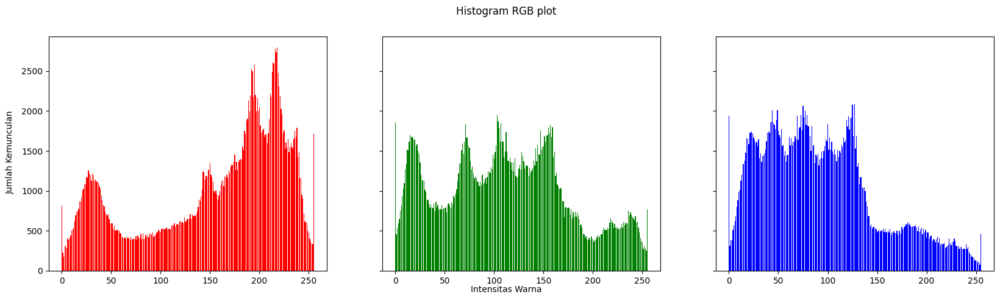

In [7]:
# membuat histogram image (manual)
img = cv.imread(source + '/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0,height) :
  for x in range(0,width) :
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1

names = np.arange(256)

fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

## PERTANYAAN PRAKTIKUM E1

### 1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu numpy.histogram, dan juga cv.calcHist. Bandingkan ketiganya dengan menghitung selisih maksimum antar hasil. Selisihnya harus nol; tampilkan pembuktiannya pada lena.jpg lebih dulu, kemudian ulangi pada KTM1b.jpg.

In [8]:
# fungsi histogram manual
def histogram_manual(img, L=256):
  height, width, depth = np.shape(img)
  hist = np.zeros((depth, L), dtype=np.int64)

  for y in range(height):
    for x in range(width):
      for c in range(depth):
        hist[c, img[y][x][c]] += 1

  return hist

# fungsi histogram NumPy
def histogram_numpy(img, L=256):
  height, width, depth = np.shape(img)
  hist = np.zeros((depth, L), dtype=np.int64)

  for c in range(depth):
    hist[c], _ = np.histogram(img[:,:,c].ravel(), bins=L, range=[0, L])

  return hist

# fungsi histogram OpenCV
def histogram_opencv(img, L=256):
  b, g, r = cv.split(img)

  h_b = cv.calcHist([b], [0], None, [L], [0, L]).flatten().astype(np.int64)
  h_g = cv.calcHist([g], [0], None, [L], [0, L]).flatten().astype(np.int64)
  h_r = cv.calcHist([r], [0], None, [L], [0, L]).flatten().astype(np.int64)

  return np.array([h_b, h_g, h_r])

In [9]:
img_lena = cv.imread(source + '/lena.jpg')
img_lena = cv.cvtColor(img_lena, cv.COLOR_BGR2RGB)

# hitung histogram dengan 3 metode
hist_manual_lena = histogram_manual(img_lena)
hist_numpy_lena = histogram_numpy(img_lena)
hist_cv_lena = histogram_opencv(img_lena)

# hitung selisih maksimum
diff_manual_numpy_lena = np.max(np.abs(hist_manual_lena - hist_numpy_lena))
diff_manual_cv_lena = np.max(np.abs(hist_manual_lena - hist_cv_lena))
diff_numpy_cv_lena = np.max(np.abs(hist_numpy_lena - hist_cv_lena))

print(f"Selisih Maks Manual vs NumPy:    {diff_manual_numpy_lena}")
print(f"Selisih Maks Manual vs OpenCV:   {diff_manual_cv_lena}")
print(f"Selisih Maks NumPy vs OpenCV:    {diff_numpy_cv_lena}")


Selisih Maks Manual vs NumPy:    0
Selisih Maks Manual vs OpenCV:   0
Selisih Maks NumPy vs OpenCV:    0


In [10]:
img_ktm1b = cv.imread(source + '/KTM1b.jpg')
img_ktm1b = cv.cvtColor(img_ktm1b, cv.COLOR_BGR2RGB)

# hitung histogram dengan 3 metode
hist_manual_ktm = histogram_manual(img_ktm1b)
hist_numpy_ktm = histogram_numpy(img_ktm1b)
hist_cv_ktm = histogram_opencv(img_ktm1b)

# hitung selisih maksimum
diff_manual_numpy_ktm = np.max(np.abs(hist_manual_ktm - hist_numpy_ktm))
diff_manual_cv_ktm = np.max(np.abs(hist_manual_ktm - hist_cv_ktm))
diff_numpy_cv_ktm = np.max(np.abs(hist_numpy_ktm - hist_cv_ktm))

print(f"Selisih Maks Manual vs NumPy:    {diff_manual_numpy_ktm}")
print(f"Selisih Maks Manual vs OpenCV:   {diff_manual_cv_ktm}")
print(f"Selisih Maks NumPy vs OpenCV:    {diff_numpy_cv_ktm}")

Selisih Maks Manual vs NumPy:    0
Selisih Maks Manual vs OpenCV:   0
Selisih Maks NumPy vs OpenCV:    0


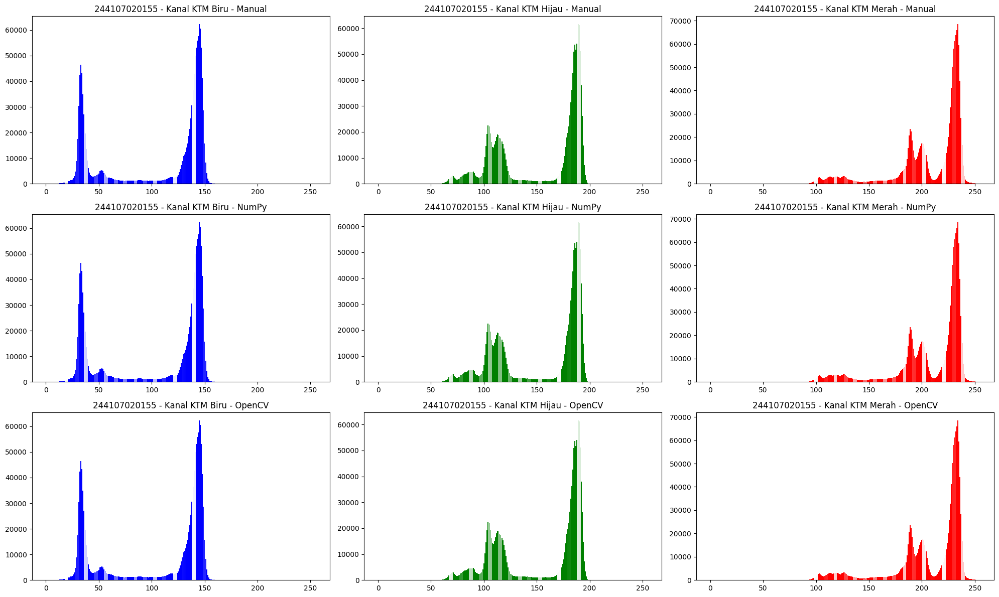

In [11]:
# output histogram ktm
names = np.arange(256)
fig, axs = plt.subplots(3, 3, figsize=[20, 12])

colors = ['blue', 'green', 'red']
channel_names = ['Biru', 'Hijau', 'Merah']

for i, (color, name) in enumerate(zip(colors, channel_names)):
  axs[0, i].bar(names, hist_manual_ktm[i], color=color)
  axs[0, i].set_title(f'244107020155 - Kanal KTM {name} - Manual', fontsize=12)

  axs[1, i].bar(names, hist_numpy_ktm[i], color=color)
  axs[1, i].set_title(f'244107020155 - Kanal KTM {name} - NumPy', fontsize=12)

  axs[2, i].bar(names, hist_cv_ktm[i], color=color)
  axs[2, i].set_title(f'244107020155 - Kanal KTM {name} - OpenCV', fontsize=12)

plt.tight_layout()
plt.show()

### 2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk KTM1a.jpg sampai KTM1d.jpg dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra paling gelap dan citra paling terang milik Anda, lalu kaitkan dengan kondisi pencahayaan saat akuisisi pada Pertemuan 2.

In [12]:
# fungsi histogram ternormalisasi p(j) dan CDF
def hitung_histogram_dan_cdf(img_gray, L=256):
  height, width = img_gray.shape
  total_pixels = height * width

  # hitung histogram manual
  hist = np.zeros(L, dtype=np.int64)
  for y in range(height):
    for x in range(width):
      hist[img_gray[y, x]] += 1

  # normalisasi: p(j) = n_j / (w*h)
  p = hist / total_pixels

  # CDF: kumulatif dari p(j)
  cdf = np.cumsum(p)

  return hist, p, cdf

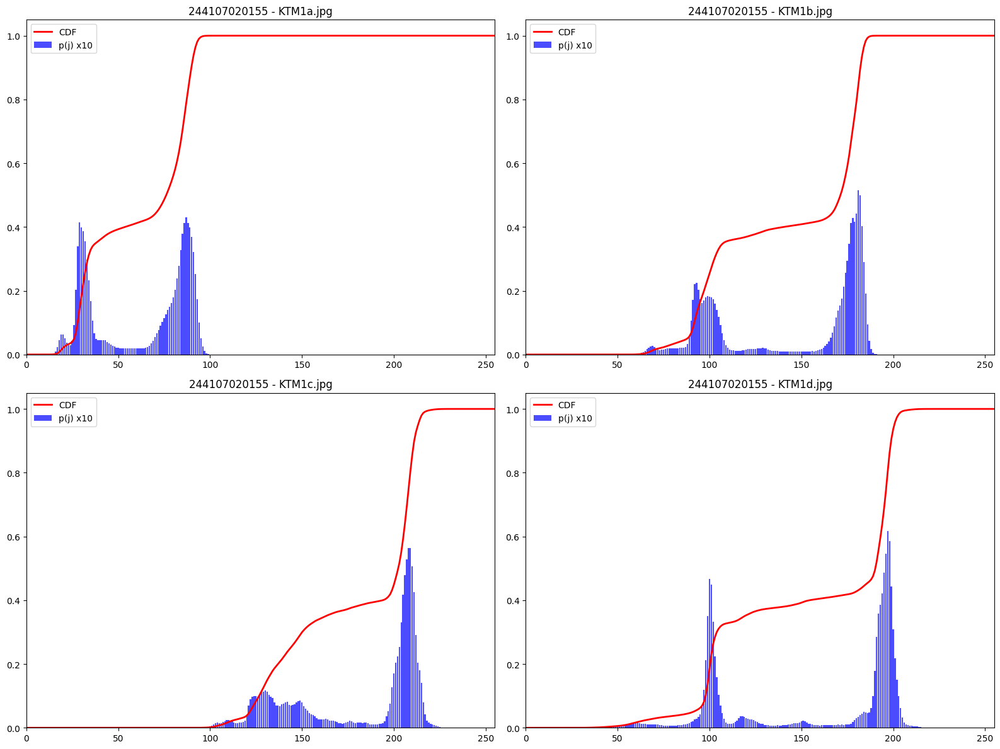

In [13]:
# 4 citra KTM (grayscale)
ktm_files = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']
ktm_images = [cv.imread(source + '/' + file, cv.IMREAD_GRAYSCALE) for file in ktm_files]

# hitung histogram dan CDF untuk setiap citra
results = []
for img in ktm_images:
  hist, p, cdf = hitung_histogram_dan_cdf(img)
  results.append((hist, p, cdf))

# output
fig, axs = plt.subplots(2, 2, figsize=[16, 12])

for idx, (file, (hist, p, cdf)) in enumerate(zip(ktm_files, results)):
  row = idx // 2
  col = idx % 2

  # histogram
  axs[row, col].bar(names, p * 10, alpha=0.7, label='p(j) x10', color='blue')
  axs[row, col].plot(names, cdf, linewidth=2, label='CDF', color='red')
  axs[row, col].set_title(f'{NIM} - {file}', fontsize=12)
  axs[row, col].legend()
  axs[row, col].set_xlim([0, 255])

plt.tight_layout()
plt.show()

Kurva CDF pada citra paling gelap (KTM1a.jpg) naik drastis di awal rentang intensitas 0-50 yang menunjukkan bahwa sebagian besar pixel terkonsentrasi pada nilai intensitas rendah. Sebaliknya CDF pada citra paling terang (KTM1d.jpg) naik drastis di intensitas tinggi 150-255 yang mengindikasikan dominasi pixel terang. Perbedaan ini karena kondisi pencahayaan saat akuisisi dimana KTM1a diambil di ruangan gelap dengan minim cahaya sehingga histogram terkumpul di area gelap, sedangkan KTM1d diambil di luar ruangan dengan cahaya matahari penuh yang menyebabkan sebagian besar pixel menjadi sangat terang.

### 3. Ulangi histogram KTM1b.jpg dengan jumlah bin sebesar PARAM['bins'] dan dengan 256 bin. Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang ketika jumlah bin dikurangi.

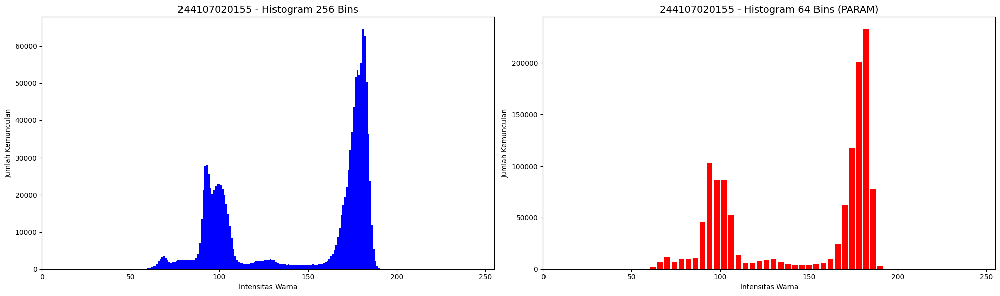

In [14]:
img_ktm1b_full = cv.imread(source + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)

# histogram dengan 256 bins
hist_256, _ = np.histogram(img_ktm1b_full.ravel(), bins=256, range=[0, 256])

# histogram dengan PARAM['bins'] bins
num_bins = PARAM['bins']
hist_param, bin_edges = np.histogram(img_ktm1b_full.ravel(), bins=num_bins, range=[0, 256])

# output
fig, axs = plt.subplots(1, 2, figsize=[20, 6])

# output 256 bins
axs[0].bar(range(256), hist_256, color='blue', width=1.0)
axs[0].set_title(f'{NIM} - Histogram 256 Bins', fontsize=14)
axs[0].set_xlabel('Intensitas Warna')
axs[0].set_ylabel('Jumlah Kemunculan')
axs[0].set_xlim([0, 255])

# output PARAM['bins'] bins
bin_centers = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in range(num_bins)]
axs[1].bar(bin_centers, hist_param, color='red', width=256/num_bins*0.8)
axs[1].set_title(f'{NIM} - Histogram {num_bins} Bins (PARAM)', fontsize=14)
axs[1].set_xlabel('Intensitas Warna')
axs[1].set_ylabel('Jumlah Kemunculan')
axs[1].set_xlim([0, 255])

plt.tight_layout()
plt.show()

Ketika jumlah bin dikurangi misalnya dari 256 menjadi PARAM['bins'] maka akan kehilangan detail sebaran warna yang halus karena satu bin kini menampung rentang pixel yang lebih lebar. Ini terjadi karena setiap bin kini mewakili rentang nilai pixel yang lebih lebar, sehingga beberapa level intensitas yang berbeda digabung menjadi satu hitungan. Akibatnya, puncak-puncak kecil pada histogram menghilang, perbedaan kontras lokal yang tipis menjadi tidak terlihat dan informasi spesifik tentang frekuensi nilai pixel tertentu menjadi tergeneralisasi dan kurang presisi.

## PERCOBAAN HISTOGRAM EQUALIZATION

### 1.

In [15]:
# fungsi manual histogram
def manual_he_rgb(img):
  height, width, depth = np.shape(img)
  img_he = np.zeros((height, width, depth), dtype=np.uint8)

  # proses setiap kanal warna (0 merah, 1 hijau, 2 biru)
  for c in range(depth):
    # menghitung jumlah frekuensi kemunculan setiap pixel
    hist = [0] * 256
    for y in range(height):
      for x in range(width):
        hist[img[y][x][c]] += 1

    # penjumlahan kumulatif (CDF) dan normalisasi
    total_pixels = height * width
    cdf = [0.0] * 256
    cdf[0] = hist[0] / total_pixels
    for i in range(1, 256):
      cdf[i] = cdf[i-1] + (hist[i] / total_pixels)

    # implementasi rumus K0 = round(CDF * (L-1)) -> L=256, dikali 255
    lookup_table = [0] * 256
    for i in range(256):
      lookup_table[i] = int(round(cdf[i] * 255))

    # transformasi kembali dalam bentuk citra
    for y in range(height):
      for x in range(width):
        img_he[y][x][c] = lookup_table[img[y][x][c]]

  return img_he

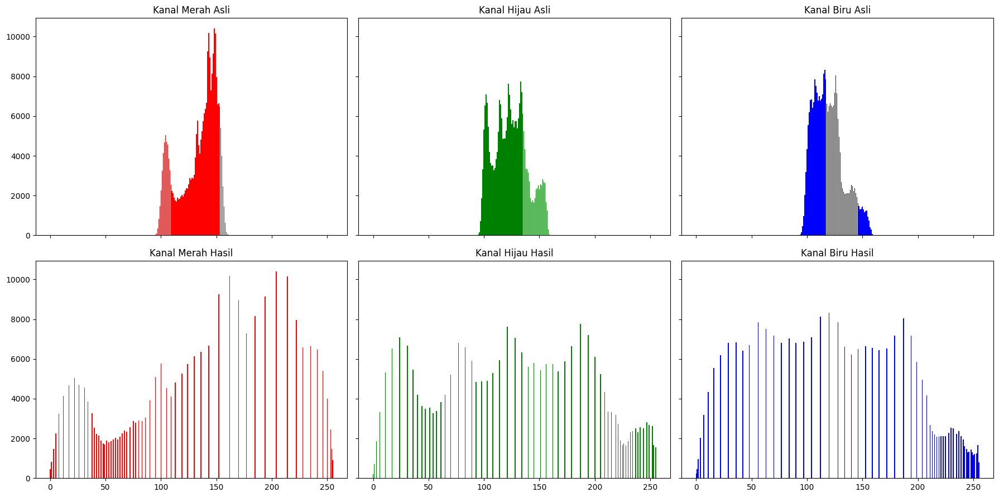

In [16]:
img_he01 = cv.imread(source + '/lena_lc.jpg')
img_he01 = cv.cvtColor(img_he01, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img_he01)
names = np.arange(256)

# hitung histogram asli
red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0, height):
  for x in range(0, width):
    red[img_he01[y][x][0]] += 1
    green[img_he01[y][x][1]] += 1
    blue[img_he01[y][x][2]] += 1

# hitung histogram equalization
img_he = manual_he_rgb(img_he01)

red_he = [0]*256
green_he = [0]*256
blue_he = [0]*256

for y in range(0, height):
  for x in range(0, width):
    red_he[img_he[y][x][0]] += 1
    green_he[img_he[y][x][1]] += 1
    blue_he[img_he[y][x][2]] += 1

# output
fig, axs = plt.subplots(2, 3, figsize=[20, 10], sharex=True, sharey=True)

# histogram asli
axs[0, 0].bar(names, red, color='red')
axs[0, 0].set_title('Kanal Merah Asli', fontsize=12)
axs[0, 1].bar(names, green, color='green')
axs[0, 1].set_title('Kanal Hijau Asli', fontsize=12)
axs[0, 2].bar(names, blue, color='blue')
axs[0, 2].set_title('Kanal Biru Asli', fontsize=12)

# hasil histogram equalization
axs[1, 0].bar(names, red_he, color='red')
axs[1, 0].set_title('Kanal Merah Hasil', fontsize=12)
axs[1, 1].bar(names, green_he, color='green')
axs[1, 1].set_title('Kanal Hijau Hasil', fontsize=12)
axs[1, 2].bar(names, blue_he, color='blue')
axs[1, 2].set_title('Kanal Biru Hasil', fontsize=12)

plt.tight_layout(rect=[0.1, 0.05, 1, 0.95])
plt.show()

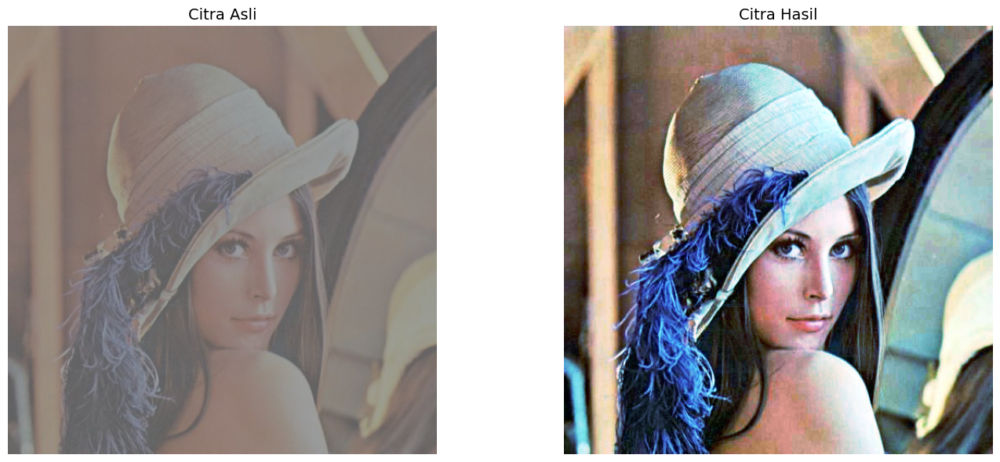

In [17]:
# output citra
fig2, axs2 = plt.subplots(1, 2, figsize=[15, 6])
axs2[0].imshow(img_he01)
axs2[0].set_title('Citra Asli', fontsize=14)
axs2[0].axis('off')

axs2[1].imshow(img_he)
axs2[1].set_title('Citra Hasil', fontsize=14)
axs2[1].axis('off')

plt.tight_layout()
plt.show()

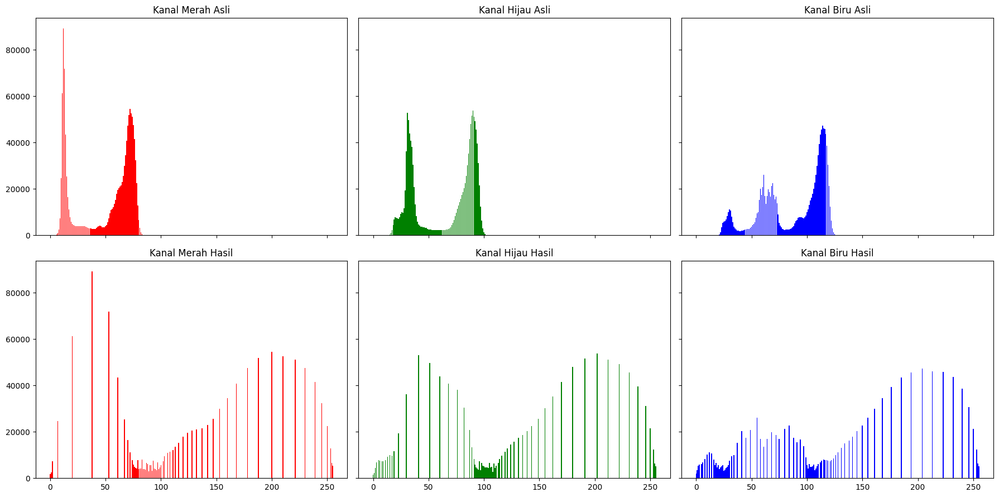

In [18]:
img_he02 = cv.imread(source + '/KTM1a.jpg')
img_he02 = cv.cvtColor(img_he02, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img_he02)
names = np.arange(256)

# hitung histogram asli
red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0, height):
  for x in range(0, width):
    red[img_he02[y][x][0]] += 1
    green[img_he02[y][x][1]] += 1
    blue[img_he02[y][x][2]] += 1

# hitung histogram equalization
img_he = manual_he_rgb(img_he02)

red_he = [0]*256
green_he = [0]*256
blue_he = [0]*256

for y in range(0, height):
  for x in range(0, width):
    red_he[img_he[y][x][0]] += 1
    green_he[img_he[y][x][1]] += 1
    blue_he[img_he[y][x][2]] += 1

# output
fig, axs = plt.subplots(2, 3, figsize=[20, 10], sharex=True, sharey=True)

# histogram asli
axs[0, 0].bar(names, red, color='red')
axs[0, 0].set_title('Kanal Merah Asli', fontsize=12)
axs[0, 1].bar(names, green, color='green')
axs[0, 1].set_title('Kanal Hijau Asli', fontsize=12)
axs[0, 2].bar(names, blue, color='blue')
axs[0, 2].set_title('Kanal Biru Asli', fontsize=12)

# hasil histogram equalization
axs[1, 0].bar(names, red_he, color='red')
axs[1, 0].set_title('Kanal Merah Hasil', fontsize=12)
axs[1, 1].bar(names, green_he, color='green')
axs[1, 1].set_title('Kanal Hijau Hasil', fontsize=12)
axs[1, 2].bar(names, blue_he, color='blue')
axs[1, 2].set_title('Kanal Biru Hasil', fontsize=12)

plt.tight_layout(rect=[0.1, 0.05, 1, 0.95])
plt.show()

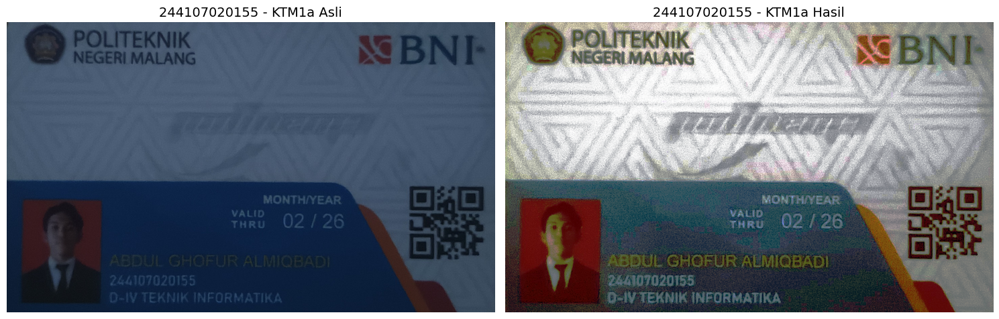

In [19]:
# output citra
fig2, axs2 = plt.subplots(1, 2, figsize=[15, 6])
axs2[0].imshow(img_he02)
axs2[0].set_title(f'{NIM} - KTM1a Asli', fontsize=14)
axs2[0].axis('off')

axs2[1].imshow(img_he)
axs2[1].set_title(f'{NIM} - KTM1a Hasil', fontsize=14)
axs2[1].axis('off')
plt.tight_layout()
plt.show()

### 2.

In [20]:
# fungsi histogram equalization menggunakan cv2
def cv2_he_rgb(img_rgb):
  r, g, b = cv.split(img_rgb)
  r_eq = cv.equalizeHist(r)
  g_eq = cv.equalizeHist(g)
  b_eq = cv.equalizeHist(b)
  return cv.merge([r_eq, g_eq, b_eq])  # merge kembali sebagai RGB


Selisih maksimum manual vs cv2.equalizeHist: 0


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

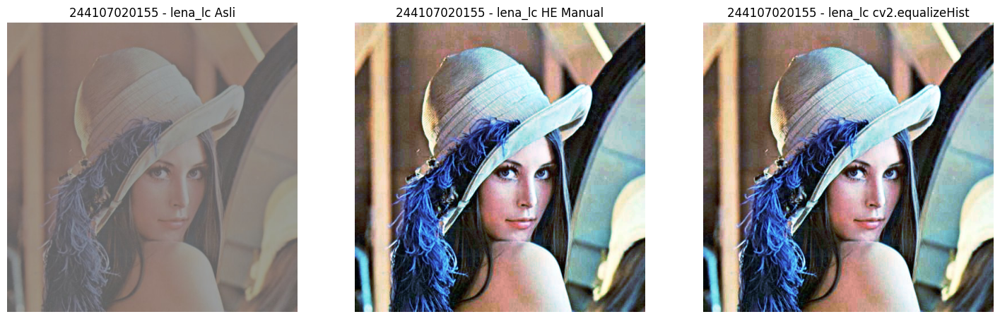

In [21]:
img_lena_lc = cv.imread(source + '/lena_lc.jpg')
img_lena_lc = cv.cvtColor(img_lena_lc, cv.COLOR_BGR2RGB)

img_lena_manual = manual_he_rgb(img_lena_lc)
img_lena_cv2 = cv2_he_rgb(img_lena_lc)

# hitung selisih maksimum
diff_lena = np.max(np.abs(img_lena_manual.astype(np.int16) - img_lena_cv2.astype(np.int16)))
print(f"Selisih maksimum manual vs cv2.equalizeHist: {diff_lena}")

# output citra
fig, axs = plt.subplots(1, 3, figsize=[18, 10])

axs[0].imshow(img_lena_lc)
axs[0].set_title(f'{NIM} - lena_lc Asli', fontsize=12)
axs[0].axis('off')

axs[1].imshow(img_lena_manual)
axs[1].set_title(f'{NIM} - lena_lc HE Manual', fontsize=12)
axs[1].axis('off')

axs[2].imshow(img_lena_cv2)
axs[2].set_title(f'{NIM} - lena_lc cv2.equalizeHist', fontsize=12)
axs[2].axis('off')

Selisish maksimum manual vs cv2.equalizeHist: 0


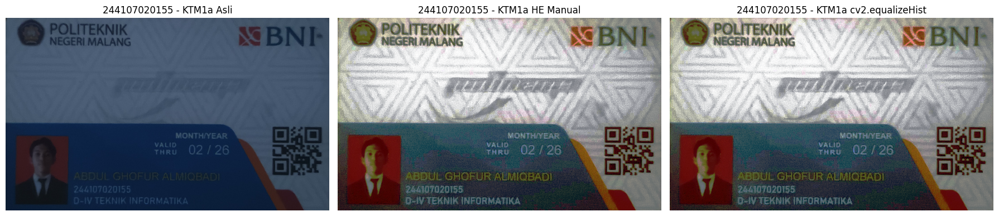

In [22]:
img_ktm_raw = cv.imread(source + '/KTM1a.jpg')
img_ktm_raw = cv.cvtColor(img_ktm_raw, cv.COLOR_BGR2RGB)

img_ktm_manual = manual_he_rgb(img_ktm_raw)
img_ktm_cv2 = cv2_he_rgb(img_ktm_raw)

diff_ktm = np.max(np.abs(img_ktm_manual.astype(np.int16) - img_ktm_cv2.astype(np.int16)))
print(f"Selisish maksimum manual vs cv2.equalizeHist: {diff_ktm}")

# output citra
fig, axs = plt.subplots(1, 3, figsize=[18, 10])

axs[0].imshow(img_ktm_raw)
axs[0].set_title(f'{NIM} - KTM1a Asli', fontsize=12)
axs[0].axis('off')

axs[1].imshow(img_ktm_manual)
axs[1].set_title(f'{NIM} - KTM1a HE Manual', fontsize=12)
axs[1].axis('off')

axs[2].imshow(img_ktm_cv2)
axs[2].set_title(f'{NIM} - KTM1a cv2.equalizeHist', fontsize=12)
axs[2].axis('off')

plt.tight_layout()
plt.show()

Hasil selisihnya 0 yang membuktikan implementasi manual sudah akurat. Namun  apabila terdapat selisih kecil disebabkan oleh perbedaan metode pembulatan pada round() pada Python vs floor() atau truncation pada C++ OpenCV, lalu perbedaan presisi komputasi yaitu antra floating-point dan fixed-point, serta optimasi internal OpenCV dalam menangani nilai frekuensi 0 atau kondisi batas intensitas.

### 3.

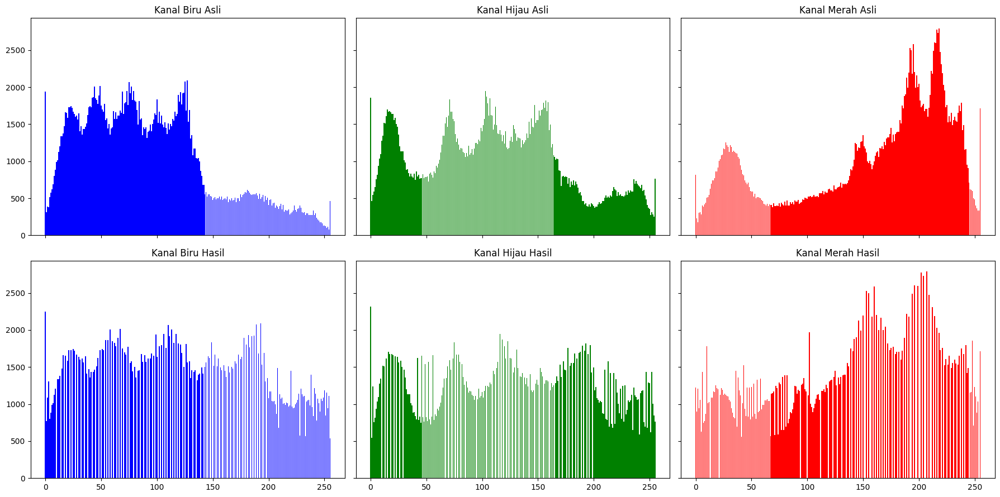

In [23]:
file = source + '/lena.jpg'
bgr = cv.imread(file)

# per kanal diekualisasi sendiri-sendiri
kanal = list(cv.split(bgr))
for i in range(3):
  kanal[i] = cv.equalizeHist(kanal[i])
he_rgb = cv.merge(kanal)

# output histogram
fig, axs = plt.subplots(2, 3, figsize=[20, 10], sharex=True, sharey=True)

names = np.arange(256)
colors = ['blue', 'green', 'red']
channel_names = ['Biru', 'Hijau', 'Merah']

# histogram asli
b_asli, g_asli, r_asli = cv.split(bgr)
for i, (ch, color, name) in enumerate(zip([b_asli, g_asli, r_asli], colors, channel_names)):
  hist = cv.calcHist([ch], [0], None, [256], [0, 256])
  axs[0, i].bar(names, hist.flatten(), color=color)
  axs[0, i].set_title(f'Kanal {name} Asli', fontsize=12)

# histogram hasil
b_he, g_he, r_he = cv.split(he_rgb)
for i, (ch, color, name) in enumerate(zip([b_he, g_he, r_he], colors, channel_names)):
  hist = cv.calcHist([ch], [0], None, [256], [0, 256])
  axs[1, i].bar(names, hist.flatten(), color=color)
  axs[1, i].set_title(f'Kanal {name} Hasil', fontsize=12)

plt.tight_layout(rect=[0.1, 0.05, 1, 0.95])
plt.show()

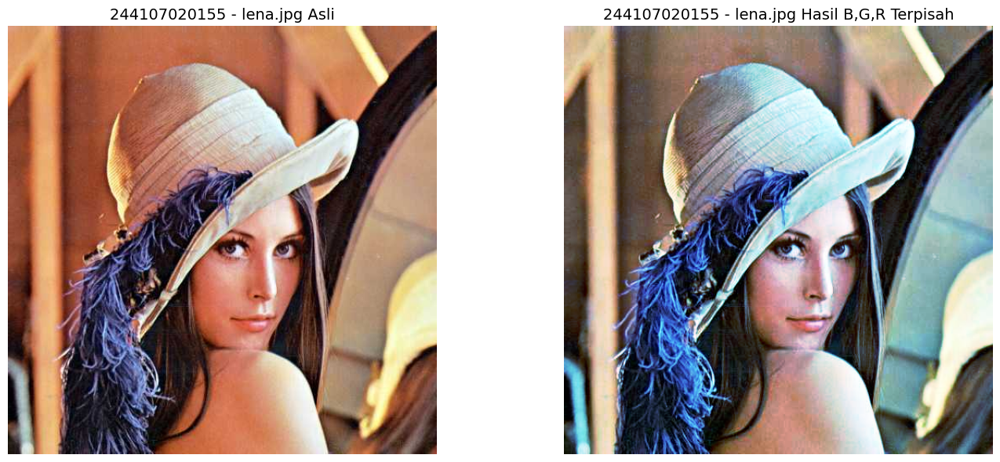

In [24]:
# output citra
fig, axs = plt.subplots(1, 2, figsize=[15, 6])

axs[0].imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
axs[0].set_title(f'{NIM} - lena.jpg Asli', fontsize=14)
axs[0].axis('off')

axs[1].imshow(cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB))
axs[1].set_title(f'{NIM} - lena.jpg Hasil B,G,R Terpisah', fontsize=14)
axs[1].axis('off')

plt.tight_layout()
plt.show()

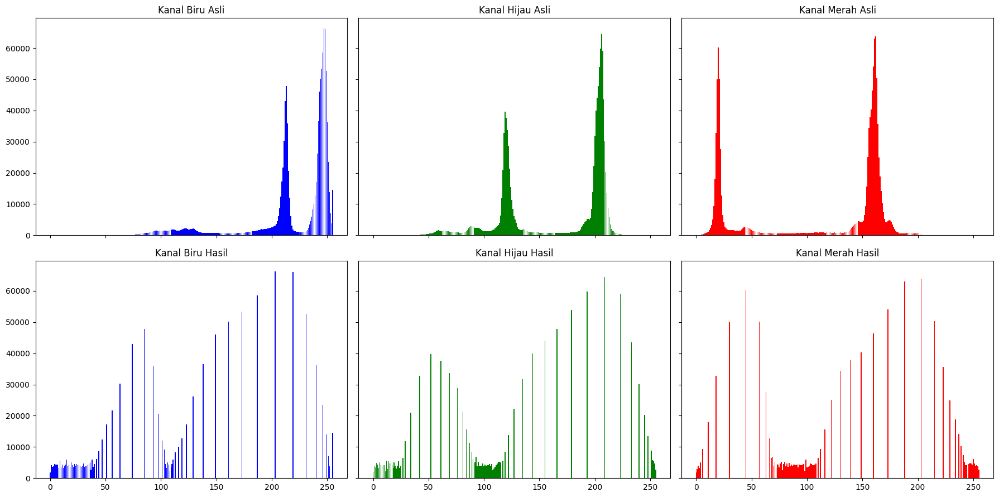

In [25]:
file2 = source + '/KTM1d.jpg'
bgr = cv.imread(file2)

# per kanal diekualisasi sendiri-sendiri
kanal = list(cv.split(bgr))
for i in range(3):
  kanal[i] = cv.equalizeHist(kanal[i])
he_rgb = cv.merge(kanal)

# output histogram
fig, axs = plt.subplots(2, 3, figsize=[20, 10], sharex=True, sharey=True)

names = np.arange(256)
colors = ['blue', 'green', 'red']
channel_names = ['Biru', 'Hijau', 'Merah']

# histogram asli
b_asli, g_asli, r_asli = cv.split(bgr)
for i, (ch, color, name) in enumerate(zip([b_asli, g_asli, r_asli], colors, channel_names)):
  hist = cv.calcHist([ch], [0], None, [256], [0, 256])
  axs[0, i].bar(names, hist.flatten(), color=color)
  axs[0, i].set_title(f'Kanal {name} Asli', fontsize=12)

# histogram hasil
b_he, g_he, r_he = cv.split(he_rgb)
for i, (ch, color, name) in enumerate(zip([b_he, g_he, r_he], colors, channel_names)):
  hist = cv.calcHist([ch], [0], None, [256], [0, 256])
  axs[1, i].bar(names, hist.flatten(), color=color)
  axs[1, i].set_title(f'Kanal {name} Hasil', fontsize=12)

plt.tight_layout(rect=[0.1, 0.05, 1, 0.95])
plt.show()

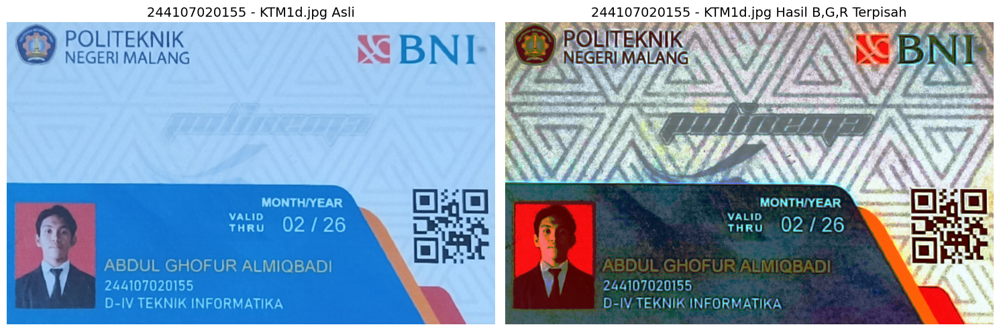

In [26]:
# outpu citra
fig, axs = plt.subplots(1, 2, figsize=[15, 6])

axs[0].imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
axs[0].set_title(f'{NIM} - KTM1d.jpg Asli', fontsize=14)
axs[0].axis('off')

axs[1].imshow(cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB))
axs[1].set_title(f'{NIM} - KTM1d.jpg Hasil B,G,R Terpisah', fontsize=14)
axs[1].axis('off')

plt.tight_layout()
plt.show()

### 4.

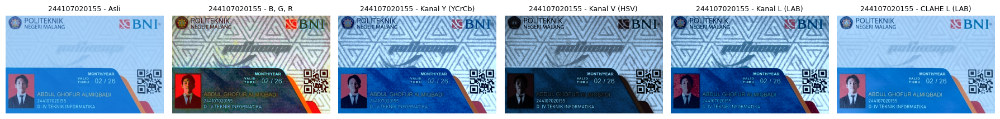

Cara Ekualisasi           Pergeseran Hue (°)   Rerata Kecerahan  
-----------------------------------------------------------------
Asli                      0.00                 157.4             
B, G, R                   53.51                131.3             
Kanal Y (YCrCb)           5.42                 133.4             
Kanal V (HSV)             0.82                 97.8              
Kanal L (LAB)             5.79                 122.2             
CLAHE L (LAB)             0.68                 154.8             


In [30]:
file = source + '/KTM1d.jpg'
bgr = cv.imread(file)

# per kanal warna
kanal = list(cv.split(bgr))
for i in range(3):
  kanal[i] = cv.equalizeHist(kanal[i])
he_rgb = cv.merge(kanal)

# hanya kanal Y dari YCrCb
ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)
y_eq = cv.equalizeHist(y)
he_y = cv.cvtColor(cv.merge([y_eq, cr, cb]), cv.COLOR_YCrCb2BGR)

# hanya kanal V ddari HSV
hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
h, sat, v = cv.split(hsv)
v_eq = cv.equalizeHist(v)
he_v = cv.cvtColor(cv.merge([h, sat, v_eq]), cv.COLOR_HSV2BGR)

# hanya kanal L dari LAB
lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b_ch = cv.split(lab)
l_eq = cv.equalizeHist(l)
he_l = cv.cvtColor(cv.merge([l_eq, a, b_ch]), cv.COLOR_LAB2BGR)

# hanya kanal L dari CLAHE
clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
l_clahe = clahe.apply(l)
he_l_clahe = cv.cvtColor(cv.merge([l_clahe, a, b_ch]), cv.COLOR_LAB2BGR)

# output citra
judul = ['Asli', 'B, G, R', 'Kanal Y (YCrCb)', 'Kanal V (HSV)', 'Kanal L (LAB)', 'CLAHE L (LAB)']
citra = [bgr, he_rgb, he_y, he_v, he_l, he_l_clahe]

plt.figure(figsize=(18, 4))
for i, (c, t) in enumerate(zip(citra, judul), 1):
  plt.subplot(1, 6, i)
  plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
  plt.title(NIM + ' - ' + t, fontsize=9)
  plt.axis('off')
plt.tight_layout()
plt.show()


# hitung pergeseran hue & rerata kecerahan
def geser_hue(asli, hasil):
  h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
  h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
  d = np.abs(h1 - h2)
  d = np.minimum(d, 180 - d)  # hue 0-179
  return d.mean()

# hitung untuk setiap metode
hasil_tabel = []
for t, c in zip(judul, citra):
  hue_shift = geser_hue(bgr, c) * 2  # *2 karena OpenCV 0-179 = 0-360 derajat
  brightness = cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
  hasil_tabel.append((t, hue_shift, brightness))

# output tabel hasil hitung
print(f"{'Cara Ekualisasi':<25} {'Pergeseran Hue (°)':<20} {'Rerata Kecerahan':<18}")
print("-" * 65)
for t, hue, bright in hasil_tabel:
  print(f"{t:<25} {hue:<20.2f} {bright:<18.1f}")

1. Ekualisasi Kanal B, G, R terpisah menghasilkan pergeseran Hue paling besar yaitu 53.51°. Hal ini terjadi karena mengubah distribusi tiap kanal secara independen merusak rasio warna asli pada setiap pixel, sehingga warna citra bergeser drastis dan terlihat tidak natural.
2. Karena proses konversi ruang warna bersifat lossy. Jadi saat citra dikembalikan ke format BGR 8-bit maka terjadi pembulatan (rounding) nilai desimal ke bilangan bulat dan pemotongan (clipping) nilai yang keluar dari rentang 0–255. Kombinasi ini mengubah rasio relatif kanal R, G, dan B, sehingga nilai Hue berubah meskipun kanal warna yaitu Cr/Cb, S, atau a/b tidak disentuh.
3. Berdasarkan hasil percobaan, Kanal Y (YCrCb) adalah yang paling sesuai untuk foto KTM dengan pergeseran Hue yang minimal yaitu 5.42° dan kecerahan yang paling natural yaitu 133.4 dibandingkan Kanal V yang terlalu gelap atau Kanal L yang agak pucat.
4. CLAHE pada Kanal L (LAB) menghasilkan pergeseran Hue minimal yaitu 0.68° dan kecerahan yang lebih seimbang yaitu 154.8 dibanding ekualisasi global di 122.2. Secara visual CLAHE membuat teks NIM lebih terbaca tanpa menimbulkan noise pada background, karena parameter clipLimit berhasil mencegah penguatan kontras yang berlebihan.

## PERTANYAAN PRAKTIKUM E2

### 1. Ekualisasi global pada citra KTM Anda
*   Terapkan ekualisasi manual dan cv.equalizeHist pada KTM1a.jpg versi
grayscale.
*   Tampilkan citra asli, citra hasil ekualisasi, serta histogram dalam satu layout.
*   Hitung PSNR antara citra asli dan citra hasil ekualisasi. Jelaskan mengapa nilai PSNR justru turun padahal citra terlihat lebih jelas, lalu simpulkan apakah PSNR
layak dipakai untuk menilai keterbacaan sebuah citra.

In [32]:
def manual_he_grayscale(img_gray):
    height, width = img_gray.shape
    total_pixels = height * width

    # 1. Menghitung frekuensi tiap intensitas
    hist = [0] * 256
    for y in range(height):
        for x in range(width):
            hist[img_gray[y, x]] += 1

    # 2 & 3. CDF dan normalisasi
    cdf = [0.0] * 256
    cdf[0] = hist[0] / total_pixels
    for i in range(1, 256):
        cdf[i] = cdf[i-1] + (hist[i] / total_pixels)

    # 4. Lookup table: K0 = round(CDF * 255)
    lookup_table = [0] * 256
    for i in range(256):
        lookup_table[i] = int(round(cdf[i] * 255))

    # 5. Transformasi citra
    img_he = np.zeros((height, width), dtype=np.uint8)
    for y in range(height):
        for x in range(width):
            img_he[y, x] = lookup_table[img_gray[y, x]]

    return img_he, hist, cdf

In [33]:
def hitung_psnr(img_asli, img_hasil):
    mse = np.mean((img_asli.astype(np.float64) - img_hasil.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    psnr = 10 * np.log10(255.0**2 / mse)
    return psnr

PSNR Asli vs Manual:        9.63 dB
PSNR Asli vs cv.equalizeHist:  9.63 dB


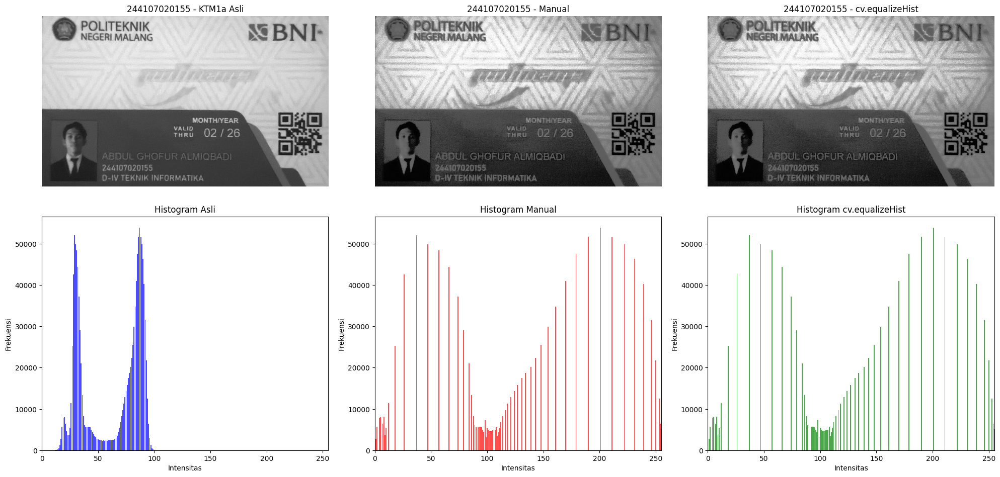

In [39]:
# baca image
img_ktm1a = cv.imread(source + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)

# ekualisasi manual
img_he_manual, hist_manual, cdf_manual = manual_he_grayscale(img_ktm1a)

# ekualisasi dengan cv2
img_he_cv2 = cv.equalizeHist(img_ktm1a)

# hitung PSNR
psnr_manual = hitung_psnr(img_ktm1a, img_he_manual)
psnr_cv2 = hitung_psnr(img_ktm1a, img_he_cv2)

print(f"PSNR Asli vs Manual:        {psnr_manual:.2f} dB")
print(f"PSNR Asli vs cv.equalizeHist:  {psnr_cv2:.2f} dB")

# output
fig, axs = plt.subplots(2, 3, figsize=[20, 10])

# citra asli
axs[0, 0].imshow(img_ktm1a, cmap='gray')
axs[0, 0].set_title(f'{NIM} - KTM1a Asli', fontsize=12)
axs[0, 0].axis('off')

# histogram asli
hist_asli = cv.calcHist([img_ktm1a], [0], None, [256], [0, 256]).flatten()
axs[1, 0].bar(names, hist_asli, color='blue', alpha=0.7)
axs[1, 0].set_title('Histogram Asli', fontsize=12)
axs[1, 0].set_xlim([0, 255])
axs[1, 0].set_xlabel('Intensitas')
axs[1, 0].set_ylabel('Frekuensi')

# citra hasil manual
axs[0, 1].imshow(img_he_manual, cmap='gray')
axs[0, 1].set_title(f'{NIM} - Manual', fontsize=12)
axs[0, 1].axis('off')

# histogram hasil manual
hist_he_manual = cv.calcHist([img_he_manual], [0], None, [256], [0, 256]).flatten()
axs[1, 1].bar(names, hist_he_manual, color='red', alpha=0.7)
axs[1, 1].set_title('Histogram Manual', fontsize=12)
axs[1, 1].set_xlim([0, 255])
axs[1, 1].set_xlabel('Intensitas')
axs[1, 1].set_ylabel('Frekuensi')

# citra hasil cv2
axs[0, 2].imshow(img_he_cv2, cmap='gray')
axs[0, 2].set_title(f'{NIM} - cv.equalizeHist', fontsize=12)
axs[0, 2].axis('off')

# histogram hasil cv2
hist_he_cv2 = cv.calcHist([img_he_cv2], [0], None, [256], [0, 256]).flatten()
axs[1, 2].bar(names, hist_he_cv2, color='green', alpha=0.7)
axs[1, 2].set_title('Histogram cv.equalizeHist', fontsize=12)
axs[1, 2].set_xlim([0, 255])
axs[1, 2].set_xlabel('Intensitas')
axs[1, 2].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()



Nilai PSNR yang rendah pada 9.63 dB terjadi karena histogram equalization mengubah nilai pixel yang dianggap sebagai error atau MSE tinggi oleh metrik, padahal secara visual kontras justru membaik. Oleh karena itu dapat disimpulkan bahwa PSNR kurang layak digunakan untuk menilai keterbacaan citra hasil ekualisasi karena metrik ini mengabaikan persepsi visual manusia terhadap peningkatan kontras.

### 2. Ekualisasi lokal dengan CLAHE pada citra KTM Anda
*   Terapkan CLAHE pada KTM1a.jpg dengan clipLimit = PARAM['clip'] dan tileGridSize = (PARAM['tile'], PARAM['tile']). Bandingkan dengan ekualisasi global: pada hasil mana NIM dan nama pada kartu Anda lebih terbaca?
*   Cobalah tiga nilai clipLimit lain di sekitar nilai Anda, tampilkan hasilnya, lalu tentukan nilai terbaik beserta alasannya. Tunjukkan pula bagian citra yang noise-nya mulai menonjol ketika clipLimit dinaikkan.

In [41]:
def floyd_steinberg(gray, L=2):
    img = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru

            if x + 1 < W:
                img[y, x + 1] += error * 7/16
            if x - 1 >= 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3/16
            if y + 1 < H:
                img[y + 1, x] += error * 5/16
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1/16

    return np.clip(img, 0, 255).astype(np.uint8)

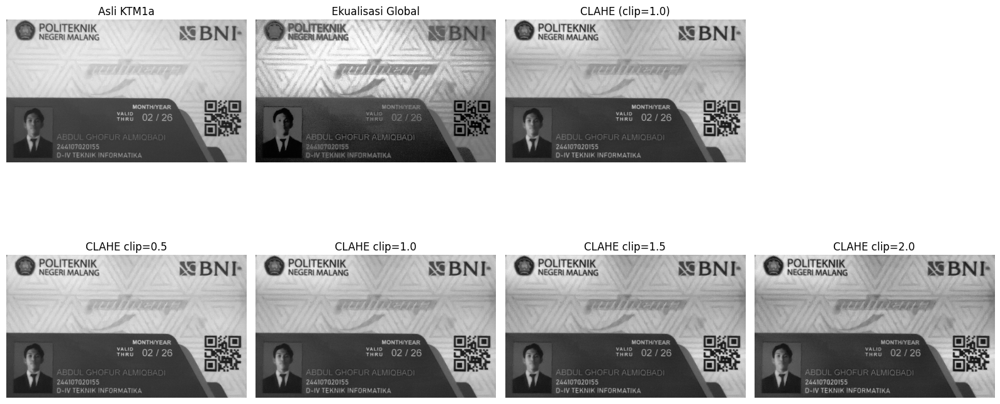

In [42]:
img_ktm1a = cv.imread(source + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)

# ekualisasi global
img_global = cv.equalizeHist(img_ktm1a)

# CLAHE dengan parameter NIM
clahe_param = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
img_clahe_param = clahe_param.apply(img_ktm1a)

# CLAHE dengan 3 nilai clipLimit lain di sekitar parameter Anda
clip_values = [
  max(0.5, PARAM['clip'] - 0.5),
  PARAM['clip'],
  PARAM['clip'] + 0.5,
  PARAM['clip'] + 1.0
]

# output
plt.figure(figsize=(16, 8))

# perbandingan dasar
plt.subplot(2, 4, 1)
plt.imshow(img_ktm1a, cmap='gray')
plt.title('Asli KTM1a')
plt.axis('off')

plt.subplot(2, 4, 2)
plt.imshow(img_global, cmap='gray')
plt.title('Ekualisasi Global')
plt.axis('off')

plt.subplot(2, 4, 3)
plt.imshow(img_clahe_param, cmap='gray')
plt.title(f"CLAHE (clip={PARAM['clip']})")
plt.axis('off')

# variasi clipLimit
for i, clip_val in enumerate(clip_values):
  clahe_temp = cv.createCLAHE(clipLimit=clip_val, tileGridSize=(PARAM['tile'], PARAM['tile']))
  img_temp = clahe_temp.apply(img_ktm1a)

  plt.subplot(2, 4, i+5)
  plt.imshow(img_temp, cmap='gray')
  plt.title(f'CLAHE clip={clip_val}')
  plt.axis('off')

plt.tight_layout()
plt.show()

# TUGAS PRAKTIKUM DITHERING

In [44]:
def floyd_steinberg(gray, L=2):
  img = gray.astype(np.float32).copy()
  step = 255.0 / (L - 1)
  H, W = img.shape

  for y in range(H):
    for x in range(W):
      lama = img[y, x]
      baru = np.round(lama / step) * step
      img[y, x] = baru
      error = lama - baru

      if x + 1 < W:
        img[y, x + 1] += error * 7/16
      if x - 1 >= 0 and y + 1 < H:
        img[y + 1, x - 1] += error * 3/16
      if y + 1 < H:
        img[y + 1, x] += error * 5/16
      if x + 1 < W and y + 1 < H:
          img[y + 1, x + 1] += error * 1/16

  return np.clip(img, 0, 255).astype(np.uint8)


def floyd_steinberg_color(img_bgr, L=2):
  b, g, r = cv.split(img_bgr)
  b_d = floyd_steinberg(b, L)
  g_d = floyd_steinberg(g, L)
  r_d = floyd_steinberg(r, L)
  return cv.merge([b_d, g_d, r_d])

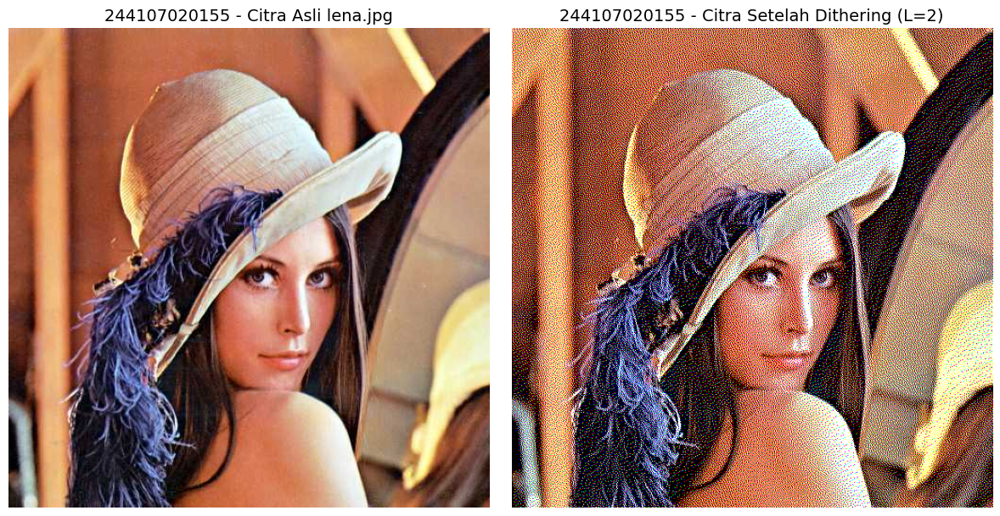

In [45]:
img_lena = cv.imread(source + '/lena.jpg')
img_lena_rgb = cv.cvtColor(img_lena, cv.COLOR_BGR2RGB)

# dithering
img_lena_dither = floyd_steinberg_color(img_lena, L=2)
img_lena_dither_rgb = cv.cvtColor(img_lena_dither, cv.COLOR_BGR2RGB)

fig, axs = plt.subplots(1, 2, figsize=[12, 6])
axs[0].imshow(img_lena_rgb)
axs[0].set_title(f'{NIM} - Citra Asli lena.jpg', fontsize=14)
axs[0].axis('off')

axs[1].imshow(img_lena_dither_rgb)
axs[1].set_title(f'{NIM} - Citra Setelah Dithering (L=2)', fontsize=14)
axs[1].axis('off')

plt.tight_layout()
plt.show()

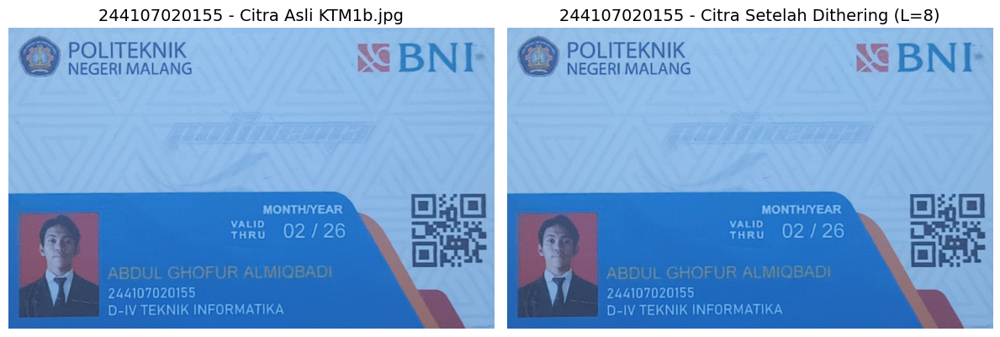

In [51]:
img_ktm1b = cv.imread(source + '/KTM1b.jpg')
img_ktm1b_rgb = cv.cvtColor(img_ktm1b, cv.COLOR_BGR2RGB)

# dithering dengan L dari PARAM NIM
img_ktm1b_dither = floyd_steinberg_color(img_ktm1b, L=PARAM['L'])
img_ktm1b_dither_rgb = cv.cvtColor(img_ktm1b_dither, cv.COLOR_BGR2RGB)

fig, axs = plt.subplots(1, 2, figsize=[12, 6])
axs[0].imshow(img_ktm1b_rgb)
axs[0].set_title(f'{NIM} - Citra Asli KTM1b.jpg', fontsize=14)
axs[0].axis('off')

axs[1].imshow(img_ktm1b_dither_rgb)
axs[1].set_title(f'{NIM} - Citra Setelah Dithering (L={PARAM["L"]})', fontsize=14)
axs[1].axis('off')

plt.tight_layout()
plt.show()

### Bagian Baru

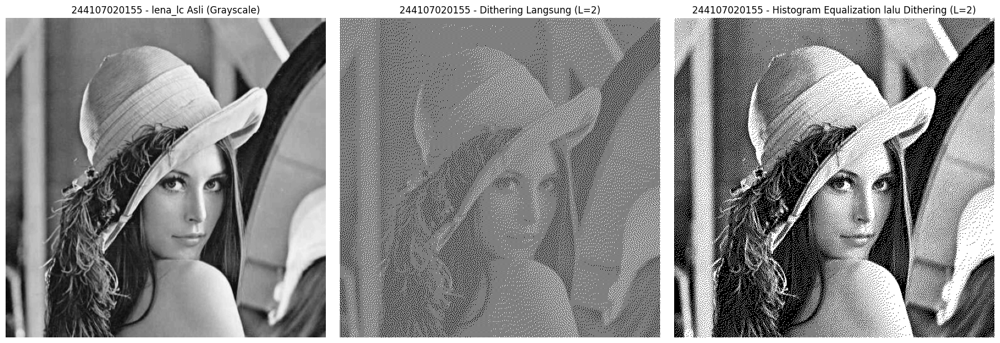

In [53]:
img_lena_lc = cv.imread(source + '/lena_lc.jpg')
img_lena_lc_gray = cv.cvtColor(img_lena_lc, cv.COLOR_BGR2GRAY)

# dithering langsung tanpa HISTOGRAM EQUALIZATION
img_lena_lc_direct = floyd_steinberg(img_lena_lc_gray, L=2)

# histogram equalization lalu dithering
img_lena_lc_he = cv.equalizeHist(img_lena_lc_gray)
img_lena_lc_he_dither = floyd_steinberg(img_lena_lc_he, L=2)

fig, axs = plt.subplots(1, 3, figsize=[18, 6])
axs[0].imshow(img_lena_lc_gray, cmap='gray')
axs[0].set_title(f'{NIM} - lena_lc Asli (Grayscale)', fontsize=12)
axs[0].axis('off')

axs[1].imshow(img_lena_lc_direct, cmap='gray')
axs[1].set_title(f'{NIM} - Dithering Langsung (L=2)', fontsize=12)
axs[1].axis('off')

axs[2].imshow(img_lena_lc_he_dither, cmap='gray')
axs[2].set_title(f'{NIM} - Histogram Equalization lalu Dithering (L=2)', fontsize=12)
axs[2].axis('off')

plt.tight_layout()
plt.show()

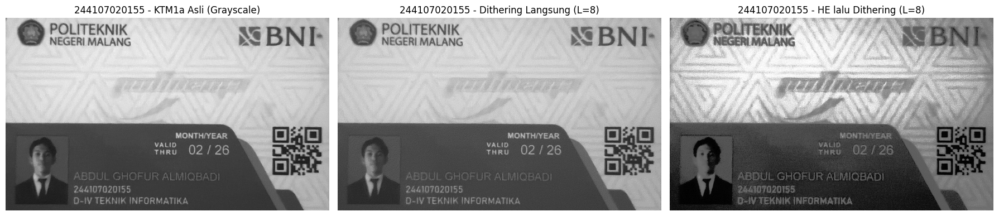

In [54]:
img_ktm1a = cv.imread(source + '/KTM1a.jpg')
img_ktm1a_gray = cv.cvtColor(img_ktm1a, cv.COLOR_BGR2GRAY)

# dithering langsung
img_ktm1a_direct = floyd_steinberg(img_ktm1a_gray, L=PARAM['L'])

# histogram equalization lalu dithering
img_ktm1a_he = cv.equalizeHist(img_ktm1a_gray)
img_ktm1a_he_dither = floyd_steinberg(img_ktm1a_he, L=PARAM['L'])

fig, axs = plt.subplots(1, 3, figsize=[18, 6])
axs[0].imshow(img_ktm1a_gray, cmap='gray')
axs[0].set_title(f'{NIM} - KTM1a Asli (Grayscale)', fontsize=12)
axs[0].axis('off')

axs[1].imshow(img_ktm1a_direct, cmap='gray')
axs[1].set_title(f'{NIM} - Dithering Langsung (L={PARAM["L"]})', fontsize=12)
axs[1].axis('off')

axs[2].imshow(img_ktm1a_he_dither, cmap='gray')
axs[2].set_title(f'{NIM} - Histogram Equalization lalu Dithering (L={PARAM["L"]})', fontsize=12)
axs[2].axis('off')

plt.tight_layout()
plt.show()